# Independent reproduction of Zhang et al. (2017), Figure 1(a–c)

**CS 6362 Advanced Machine Learning — Assignment 2 (Phase 2/3).** This notebook implements the experiments *independently from the research paper*. No authors' or third-party reproduction implementation was consulted.

**Source:** Zhang, Bengio, Hardt, Recht & Vinyals, *Understanding Deep Learning Requires Rethinking Generalization* (ICLR 2017), especially Section 2.1, Figure 1, Appendix A and Figure 3. [Paper (arXiv)](https://arxiv.org/abs/1611.03530). **Do not inspect any external implementation until this Phase 3 version is committed.**

| Figure panel | What is trained | What we plot |
|:--|:--|:--|
| 1a | Small Inception, five fixed-once label/image conditions | Actual minibatch cross-entropy against optimizer steps |
| 1b | Small Inception, adapted AlexNet, MLP 1×512 at increasing p | Steps to operational convergence, divided by same model's p=0 steps |
| 1c | Same trained runs | Error against original test labels at the first converged epoch |

**Integrity rule:** Plots come from actual SGD training logs. We do not synthesize or hardcode learning curves. An abbreviated 1024-image smoke test is **not** a valid reproduction of the paper's figure.

## 0. Environment setup

Recommended: **Google Colab → Runtime → Change runtime type → GPU**. A CUDA GPU will speed up these many-run experiments. Apple Silicon `mps` is an option on an M2 Pro, though slower and dependent on compatible PyTorch operations. The environment below uses whichever of CUDA, MPS, and CPU is available.

Colab usually already includes PyTorch, torchvision, NumPy and Matplotlib. If needed, uncomment the install line *then restart the runtime*. Be careful not to replace a GPU-enabled Colab torch build with CPU-only packages.

If runtime disconnects, rerunning with identical configuration can resume from the last completed epoch (when checkpoints were saved). For persistence across Colab runtime resets, change `out_dir` below to a mounted Google Drive path.

In [6]:
# Uncomment ONLY if one of these packages is missing:
# %pip install -q torch torchvision numpy matplotlib

import os, platform, sys
import torch, torchvision, numpy as np, matplotlib
print('Python:', sys.version.split()[0], '| torch:', torch.__version__,
      '| torchvision:', torchvision.__version__)
print('CUDA available:', torch.cuda.is_available(),
      '| MPS available:', bool(getattr(torch.backends, 'mps', None) and torch.backends.mps.is_available()))
if torch.cuda.is_available():
    print('CUDA GPU:', torch.cuda.get_device_name(0))

Python: 3.13.15 | torch: 2.11.0+cu130 | torchvision: 0.26.0+cu130
CUDA available: True | MPS available: False
CUDA GPU: NVIDIA A100-SXM4-40GB


## 1. Independent implementation

The following cell writes **our own** PyTorch implementation alongside the notebook. It is self-contained; no GitHub cloning, external implementations, pretrained weights or scripted result values. It defines:

- Fixed-once corruption and image transformations, center crop + TensorFlow-like per-image whitening
- The Inception diagram reconstruction, an AlexNet with convolution/pool/LRN blocks, and 512-wide MLPs
- SGD with momentum + exponential LR decay, full training-set and test-set evaluations, JSON logging, and end-of-epoch checkpointing
- Three plotting panels driven *exclusively* by optimizer-produced measurements

**Known unresolved discrepancy:** Appendix Figure 3-based Inception has **1,577,306** trainable parameters here; Table 1 says **1,649,402**. The discrepancy is reported rather than hidden. AlexNet / MLP counts match exactly. See `DECISIONS.md` in the downloaded archive.

In [7]:
%%writefile zhang_figure1_independent.py
"""Independent, paper-derived reproduction of Zhang et al. (2017), Figure 1.
No third-party reproduction code consulted. See notebook and DECISIONS.md.
Requires torch, torchvision, numpy, matplotlib. CIFAR-10 downloaded by torchvision.
"""
import gc
import hashlib
import json
import math
import os
import platform
import random
import time
from dataclasses import asdict, dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision.datasets import CIFAR10

PAPER_PARAM_COUNTS = {'inception': 1649402, 'alexnet': 1387786,
                      'mlp1': 1209866, 'mlp3': 1735178}
INPUT_DIM = 3 * 28 * 28


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def choose_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if getattr(torch.backends, 'mps', None) and torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def tf_per_image_whiten(image):
    """TensorFlow per_image_whitening: one scalar mean/std over ALL 2352 entries.

    Paper: [0,1] scaling -> center crop to 28x28 -> whitening.
    TensorFlow adjusted_std = max(population std, 1/sqrt(num_elements)).
    """
    x = image.float()
    mean = x.mean()
    sd = torch.sqrt(((x - mean) ** 2).mean())
    adjusted = sd.clamp(min=1.0 / math.sqrt(x.numel()))
    return (x - mean) / adjusted


def corrupted_labels(true_labels, p, seed=2027):
    """Nested corruption: fixed uniform draws and fixed random classes for all p.
    At p=1 each replacement is uniform over 10 classes, including the true one.
    """
    if not 0.0 <= float(p) <= 1.0:
        raise ValueError('Corruption probability must be in [0, 1].')
    original = np.asarray(true_labels, dtype=np.int64)
    rng = np.random.default_rng(seed)
    selected = rng.random(original.size) < p
    draws = rng.integers(0, 10, size=original.size, dtype=np.int64)
    modified = original.copy()
    modified[selected] = draws[selected]
    return modified, selected


class CIFARCondition(Dataset):
    """Fixed-once image transformation and label targets, including across epochs.

    `raw_images` is original CIFAR-10 HWC uint8 array. A condition object is
    constructed ONCE per run; never regenerate transformations in __getitem__.
    """
    def __init__(self, raw_images, labels, image_mode='true', image_seed=123,
                 gaussian_mean=None, gaussian_std=None):
        self.targets = np.asarray(labels, dtype=np.int64).copy()
        self.mode = image_mode
        self.images = np.ascontiguousarray(raw_images[:, 2:30, 2:30, :].transpose(0, 3, 1, 2))
        if len(self.images) != len(self.targets):
            raise ValueError('Images and labels must have matching lengths')
        n, c, h, w = self.images.shape
        rng = np.random.default_rng(image_seed)
        if image_mode == 'true':
            pass
        elif image_mode == 'shuffled_pixels':
            # One global permutation across all spatial positions and channels.
            perm = rng.permutation(c * h * w)
            self.images = self.images.reshape(n, -1)[:, perm].reshape(n, c, h, w).copy()
            self.permutation = perm
        elif image_mode == 'random_pixels':
            # Per-example independent permutation. Precompute: no epoch resampling.
            flat = self.images.reshape(n, -1)
            scrambled = np.empty_like(flat)
            for i in range(n):
                scrambled[i] = flat[i, rng.permutation(flat.shape[1])]
            self.images = scrambled.reshape(n, c, h, w)
        elif image_mode == 'gaussian':
            if gaussian_mean is None or gaussian_std is None:
                raise ValueError('Gaussian condition requires train image mean/std')
            self.images = rng.normal(gaussian_mean, gaussian_std,
                                     size=(n, c, h, w)).astype(np.float32)
            # Already in [0,1] units (though Gaussian is unbounded).
        else:
            raise ValueError(f'Unknown image mode: {image_mode}')

    def __len__(self):
        return len(self.targets)

    def __getitem__(self, index):
        x = torch.from_numpy(self.images[index])
        if self.mode != 'gaussian':
            x = x.float().div_(255.0)
        # Whiten after the input transformation.
        return tf_per_image_whiten(x), int(self.targets[index])


def load_cifar(root='./data', limit=None):
    train = CIFAR10(root=root, train=True, download=True)
    test = CIFAR10(root=root, train=False, download=True)
    tr_x, tr_y = train.data, np.asarray(train.targets, dtype=np.int64)
    te_x, te_y = test.data, np.asarray(test.targets, dtype=np.int64)
    if limit is not None:
        tr_x, tr_y = tr_x[:limit], tr_y[:limit]
        # Smoke-mode test subset is only for checking mechanics.
        te_x, te_y = te_x[:max(100, min(1000, limit // 2))], te_y[:max(100, min(1000, limit // 2))]
    return (tr_x, tr_y), (te_x, te_y)


class ConvBNReLU(nn.Sequential):
    def __init__(self, input_ch, output_ch, kernel=3, stride=1):
        super().__init__(
            nn.Conv2d(input_ch, output_ch, kernel_size=kernel, stride=stride,
                      padding=kernel // 2, bias=True),
            nn.BatchNorm2d(output_ch),
            nn.ReLU(inplace=True))


class InceptionBlock(nn.Module):
    """Figure 3: parallel direct 1x1 and 3x3 Conv-BN-ReLU branches."""
    def __init__(self, input_ch, ch1, ch3):
        super().__init__()
        self.one = ConvBNReLU(input_ch, ch1, 1)
        self.three = ConvBNReLU(input_ch, ch3, 3)

    def forward(self, x):
        return torch.cat((self.one(x), self.three(x)), dim=1)


class DownsampleBlock(nn.Module):
    """Figure 3: stride-2 convolution concatenated with stride-2 maxpool."""
    def __init__(self, input_ch, conv_ch):
        super().__init__()
        self.conv = ConvBNReLU(input_ch, conv_ch, 3, stride=2)
        self.pool = nn.MaxPool2d(kernel_size=3, stride=2, padding=1)

    def forward(self, x):
        return torch.cat((self.conv(x), self.pool(x)), dim=1)


class SmallInception(nn.Module):
    """Figure 3 reconstruction, not torchvision's Inception-v3.

    IMPORTANT: this literal reconstruction yields 1,577,306 trainable parameters,
    while Table 1 reports 1,649,402. Discrepancy remains UNRESOLVED and logged;
    we do not add arbitrary parameters merely to match the reference count.
    """
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            ConvBNReLU(3, 96, 3),
            InceptionBlock(96, 32, 32),
            InceptionBlock(64, 32, 48),
            DownsampleBlock(80, 80),
            InceptionBlock(160, 80, 80),
            InceptionBlock(160, 48, 96),
            DownsampleBlock(144, 96),
            InceptionBlock(240, 96, 64),
            InceptionBlock(160, 112, 48),
            InceptionBlock(160, 176, 160),
            InceptionBlock(336, 176, 160),
        )
        self.classifier = nn.Linear(336, 10)

    def forward(self, x):
        x = self.features(x)
        x = x.mean(dim=(2, 3))  # paper: 7x7 global mean pooling
        return self.classifier(x)


class SmallAlexNet(nn.Module):
    """Figure A: two conv5->pool3->LRN blocks, 384, 192 dense units.

    Paper's exact 1,387,786 parameters recover with 64 conv channels each,
    same-padded convs, stride-2 same-padded pooling, and 7x7 final map.
    LRN hyperparameters are not given by the paper: standard AlexNet-like choice.
    """
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 64, 5, padding=2), nn.ReLU(inplace=True),
            nn.MaxPool2d(3, stride=2, padding=1),
            nn.LocalResponseNorm(size=5, alpha=1e-4, beta=0.75, k=2),
            nn.Conv2d(64, 64, 5, padding=2), nn.ReLU(inplace=True),
            nn.MaxPool2d(3, stride=2, padding=1),
            nn.LocalResponseNorm(size=5, alpha=1e-4, beta=0.75, k=2),
            nn.Flatten(),
        )
        self.classifier = nn.Sequential(
            nn.Linear(64*7*7, 384), nn.ReLU(inplace=True),
            nn.Linear(384, 192), nn.ReLU(inplace=True),
            nn.Linear(192, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


class MLP(nn.Module):
    def __init__(self, depth=1):
        super().__init__()
        layers = [nn.Flatten()]
        ins = INPUT_DIM
        for _ in range(depth):
            layers += [nn.Linear(ins, 512), nn.ReLU(inplace=True)]
            ins = 512
        layers += [nn.Linear(ins, 10)]
        self.layers = nn.Sequential(*layers)

    def forward(self, x):
        return self.layers(x)


def create_model(name):
    if name == 'inception': return SmallInception()
    if name == 'alexnet': return SmallAlexNet()
    if name == 'mlp1': return MLP(1)
    if name == 'mlp3': return MLP(3)
    raise ValueError(f'Unknown model: {name}')


def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def architecture_diagnostics():
    table = []
    for name, expected in PAPER_PARAM_COUNTS.items():
        model = create_model(name)
        actual = count_parameters(model)
        with torch.no_grad():
            model.eval()
            y = model(torch.randn(2, 3, 28, 28))
        assert y.shape == (2, 10), (name, y.shape)
        if name != 'inception':
            assert actual == expected, (name, actual, expected)
        table.append({'model': name, 'params_actual': actual,
                      'params_paper': expected, 'difference': actual - expected})
    return table


def data_diagnostics(train_raw, train_labels, image_seed=123, label_seed=2027):
    small_x, small_y = train_raw[:32], train_labels[:32]
    true = CIFARCondition(small_x, small_y, 'true')
    x, label = true[0]
    assert x.shape == (3, 28, 28) and x.dtype == torch.float32
    assert abs(x.mean().item()) < 1e-5
    assert float(x.std(unbiased=False)) > 0.98
    shuffled = CIFARCondition(small_x, small_y, 'shuffled_pixels', image_seed=image_seed)
    # Equal pixel multisets, different spatial arrangement.
    assert np.array_equal(np.sort(true.images[0].ravel()),
                          np.sort(shuffled.images[0].ravel()))
    assert np.array_equal(shuffled.images[0].ravel(),
                          true.images[0].ravel()[shuffled.permutation])
    shuffled_again = CIFARCondition(small_x, small_y, 'shuffled_pixels', image_seed=image_seed)
    assert np.array_equal(shuffled.images, shuffled_again.images)
    random_px = CIFARCondition(small_x, small_y, 'random_pixels', image_seed=image_seed)
    assert np.array_equal(np.sort(true.images[1].ravel()),
                          np.sort(random_px.images[1].ravel()))
    assert np.array_equal(random_px.images, CIFARCondition(small_x, small_y,
                          'random_pixels', image_seed=image_seed).images)
    p0, _ = corrupted_labels(train_labels, 0.0, label_seed)
    p1, mask = corrupted_labels(train_labels, 1.0, label_seed)
    assert np.array_equal(p0, train_labels)
    assert mask.all() and np.array_equal(p1, corrupted_labels(train_labels, 1.0, label_seed)[0])
    observed = float(np.mean(p1 != train_labels))
    assert abs(observed - 0.9) < max(0.03, 4 * math.sqrt(0.09 / len(train_labels))), observed
    return {'whitened_sample_mean': float(x.mean()),
            'whitened_sample_population_std': float(x.std(unbiased=False)),
            'p1_fraction_labels_actually_changed': observed,
            'test_labels': 'Always original, never corrupted'}


@dataclass
class ExperimentConfig:
    run_mode: str = 'smoke'       # smoke | reduced | full
    data_root: str = './data'
    out_dir: str = './zhang_results'
    batch_size: int = 128         # NOT specified in Appendix A; explicit choice
    label_seed: int = 2027
    image_seed: int = 990
    init_seed: int = 2026
    num_workers: int = 0
    logging_interval_steps: int = 50
    converge_train_accuracy: float = 0.99  # choice, see notes and Table 1
    max_epochs: int = 200  # runs are censored if 99% not reached within budget
    smoke_size: int = 1024
    figure1a_max_steps: int = 25000
    checkpoint: bool = True  # end-of-epoch model/optimizer/RNG states to resume


def condition_id(model_name, corruption_p, image_mode, config):
    return f'{model_name}_p{corruption_p:.2f}_{image_mode}_n{config.smoke_size if config.run_mode == "smoke" else 50000}_{config.run_mode}'


def epoch_eval(model, loader, device):
    # Independent full-dataset evaluation in model.eval() (important for BN).
    was_training = model.training
    model.eval()
    correct, total, running_loss = 0, 0, 0.0
    with torch.inference_mode():
        for x, y in loader:
            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)
            logits = model(x)
            loss = nn.functional.cross_entropy(logits, y, reduction='sum')
            running_loss += float(loss.detach().cpu())
            correct += int((logits.argmax(dim=1) == y).sum())
            total += len(y)
    if was_training:
        model.train()
    return {'loss': running_loss / total, 'accuracy': correct / total,
            'errors': total - correct, 'total': total}


def execute_run(model_name, p, image_mode, config, train_source, test_source,
                device=None, max_epochs=None, max_steps=None, stop_at_convergence=False):
    """The only source of figure data: genuinely executed optimization steps.

    Metrics/results are saved immediately per epoch; completed runs can be re-used.
    This function does not resume interrupted runs; reruns overwrite that run's log.
    """
    device = device or choose_device()
    out = Path(config.out_dir)
    out.mkdir(parents=True, exist_ok=True)
    identifier = condition_id(model_name, p, image_mode, config)
    path = out / (identifier + '.json')
    checkpoint_path = out / (identifier + '.pt')
    requested = {'model': model_name, 'p': float(p), 'image_mode': image_mode,
                 'config': asdict(config), 'max_epochs': max_epochs or config.max_epochs,
                 'max_steps': max_steps, 'stop_at_convergence': stop_at_convergence}
    key = hashlib.sha256(json.dumps(requested, sort_keys=True).encode()).hexdigest()[:16]
    old = None
    if path.exists():
        old = json.loads(path.read_text())
        if old.get('run_key') == key and old.get('completed', False):
            print('Using previously completed actual run:', identifier)
            return old
    train_raw, train_true_y = train_source
    test_raw, test_true_y = test_source
    labels, selected = corrupted_labels(train_true_y, p, config.label_seed)
    center = train_raw[:, 2:30, 2:30, :].astype(np.float32) / 255.0
    gmean = float(center.mean(dtype=np.float64))
    gstd = float(center.std(dtype=np.float64))
    del center
    dataset = CIFARCondition(train_raw, labels, image_mode,
                             image_seed=config.image_seed,
                             gaussian_mean=gmean, gaussian_std=gstd)
    # Match the paper's train/test input condition; labels on test stay TRUE.
    # Shared shuffled-pixel permutation requires the same seed on both splits.
    test_seed = config.image_seed if image_mode == 'shuffled_pixels' else config.image_seed + 123456
    test_dataset = CIFARCondition(test_raw, test_true_y, image_mode,
                                  image_seed=test_seed,
                                  gaussian_mean=gmean, gaussian_std=gstd)
    generator = torch.Generator().manual_seed(config.init_seed + 99)
    train_loader = DataLoader(dataset, batch_size=config.batch_size,
                              shuffle=True, generator=generator,
                              num_workers=config.num_workers,
                              pin_memory=device.type == 'cuda')
    accuracy_loader = DataLoader(dataset, batch_size=config.batch_size * 2,
                                 shuffle=False, num_workers=config.num_workers,
                                 pin_memory=device.type == 'cuda')
    test_loader = DataLoader(test_dataset, batch_size=config.batch_size * 2,
                             shuffle=False, num_workers=config.num_workers,
                             pin_memory=device.type == 'cuda')
    seed_everything(config.init_seed)  # identical initialization for all p and modes
    model = create_model(model_name).to(device)
    lr = .1 if model_name == 'inception' else .01
    opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=.9, weight_decay=0.)
    scheduler = torch.optim.lr_scheduler.ExponentialLR(opt, gamma=.95)
    record = dict(run_key=key, run_id=identifier, requested=requested,
                  completed=False, start_time_utc=time.strftime('%Y-%m-%dT%H:%M:%SZ', time.gmtime()),
                  device=str(device), torch_version=torch.__version__,
                  parameter_count=count_parameters(model),
                  actual_changed_fraction=float(np.mean(labels != train_true_y)),
                  selected_fraction=float(selected.mean()),
                  train_size=len(dataset), test_size=len(test_dataset),
                  gaussian_input_mean=gmean, gaussian_input_sd=gstd,
                  batch_losses=[], epoch_metrics=[], convergence_steps=None,
                  convergence_epoch=None, converged=False, test_at_convergence=None, test_at_end=None,
                  training_steps=0, status='running')
    num_epochs = max_epochs if max_epochs is not None else config.max_epochs
    max_steps = int(max_steps) if max_steps is not None else None
    started = time.monotonic()
    first_epoch = 1
    if (config.checkpoint and checkpoint_path.exists() and old is not None
            and old.get('run_key') == key and not old.get('completed', False)):
        # Files written after an epoch, so resuming starts at the next epoch.
        # weights_only=False: safe here only because this is our own local file.
        ckpt = torch.load(checkpoint_path, map_location='cpu', weights_only=False)
        if ckpt.get('run_key') == key:
            model.load_state_dict(ckpt['model'])
            opt.load_state_dict(ckpt['optimizer'])
            # After optimizer state load, move momentum buffers to active device.
            for st in opt.state.values():
                for k, v in st.items():
                    if torch.is_tensor(v): st[k] = v.to(device)
            scheduler.load_state_dict(ckpt['scheduler'])
            generator.set_state(ckpt['data_generator_state'])
            torch.set_rng_state(ckpt['torch_rng'])
            if device.type == 'cuda' and ckpt.get('cuda_rng') is not None:
                torch.cuda.set_rng_state_all(ckpt['cuda_rng'])
            record = ckpt['record']
            first_epoch = ckpt['completed_epoch'] + 1
            print(f'Resuming validated checkpoint: {identifier} at epoch {first_epoch}')
    criterion = nn.CrossEntropyLoss()
    try:
        for epoch in range(first_epoch, num_epochs + 1):
            model.train()
            lr_this_epoch = float(opt.param_groups[0]['lr'])
            epoch_train_loss_sum, seen = 0.0, 0
            for x, y in train_loader:
                x = x.to(device, non_blocking=True)
                y = y.to(device, non_blocking=True)
                opt.zero_grad(set_to_none=True)
                logits = model(x)
                loss = criterion(logits, y)
                loss.backward()
                opt.step()
                record['training_steps'] += 1
                loss_value = float(loss.detach().cpu())
                epoch_train_loss_sum += loss_value * len(y)
                seen += len(y)
                if record['training_steps'] == 1 or record['training_steps'] % config.logging_interval_steps == 0:
                    record['batch_losses'].append({'step': record['training_steps'], 'loss': loss_value})
                if max_steps is not None and record['training_steps'] >= max_steps:
                    break
            # Separate full training-set evaluation, not only stochastic minibatch accuracy.
            tr = epoch_eval(model, accuracy_loader, device)
            record['epoch_metrics'].append(dict(epoch=epoch, step=record['training_steps'],
                lr=lr_this_epoch, minibatch_loss=epoch_train_loss_sum / max(1, seen),
                train_loss=tr['loss'], train_accuracy=tr['accuracy'],
                train_errors=tr['errors']))
            if record['convergence_steps'] is None and tr['accuracy'] >= config.converge_train_accuracy:
                record['convergence_steps'] = int(record['training_steps'])
                record['convergence_epoch'] = int(epoch)
                record['converged'] = True
                record['test_at_convergence'] = epoch_eval(model, test_loader, device)
            scheduler.step()
            record['runtime_seconds'] = float(time.monotonic()-started)
            if config.checkpoint:
                temp = checkpoint_path.with_suffix('.tmp')
                torch.save({'run_key': key, 'completed_epoch': epoch,
                            'model': model.state_dict(),
                            'optimizer': opt.state_dict(),
                            'scheduler': scheduler.state_dict(),
                            'data_generator_state': generator.get_state(),
                            'torch_rng': torch.get_rng_state(),
                            'cuda_rng': (torch.cuda.get_rng_state_all() if device.type == 'cuda' else None),
                            'record': record}, temp)
                os.replace(temp, checkpoint_path)
            path.write_text(json.dumps(record, indent=2))
            print(f'{identifier} epoch {epoch:03}  step {record["training_steps"]:06} '
                  f'train CE {tr["loss"]:.4f}  acc {tr["accuracy"]:.4%} '
                  f'LR {lr_this_epoch:.5g}')
            if (stop_at_convergence and record['converged']) or (max_steps is not None and record['training_steps'] >= max_steps):
                break
        record['test_at_end'] = epoch_eval(model, test_loader, device)
        record['completed'] = True
        record['status'] = 'converged' if record['converged'] else 'budget_exhausted_not_converged'
        record['runtime_seconds'] = float(time.monotonic()-started)
        record['finished_at_utc'] = time.strftime('%Y-%m-%dT%H:%M:%SZ', time.gmtime())
        path.write_text(json.dumps(record, indent=2))
        if checkpoint_path.exists() and config.checkpoint:
            checkpoint_path.unlink()  # completed runs only need summary JSON
    finally:
        del dataset, train_loader, accuracy_loader, test_dataset, test_loader, model, opt, scheduler
        gc.collect()
        if device.type == 'cuda':
            torch.cuda.empty_cache()
    return record


def run_all(config):
    """Runs 1a + 1b/c. No plots are generated from anything but run JSON records.

    smoke: 1a true/random labels + MLP p0, p1, n=1024, 2 epochs.
    reduced: 1a five conditions; 1b/c three models p={0,.5,1}; full CIFAR.
    full: 1a five conditions; 1b/c three models p={0,.1,...,1}; full CIFAR.
    Reuse Inception p0 and p1 for both panels with identical training settings.
    """
    if config.run_mode not in ('smoke', 'reduced', 'full'):
        raise ValueError('run_mode must be smoke, reduced, or full')
    device = choose_device()
    print('Device:', device, 'PyTorch:', torch.__version__)
    print('WARNING: model Inception count mismatches paper; see DECISIONS.md')
    arch_report = architecture_diagnostics()
    print('Architecture diagnostics:', arch_report)
    subset = config.smoke_size if config.run_mode == 'smoke' else None
    train_data, test_data = load_cifar(config.data_root, subset)
    print('Data diagnostics:', data_diagnostics(*train_data,
                                            image_seed=config.image_seed,
                                            label_seed=config.label_seed))
    if config.run_mode == 'smoke':
        a_conditions = [('true', 0.), ('true', 1.)]
        probabilities = [0., 1.]
        grid_models = ['mlp1']
        epochs = 2
        steps_limit = None
    elif config.run_mode == 'reduced':
        a_conditions = [('true', 0.), ('true', 1.), ('shuffled_pixels', 0.),
                        ('random_pixels', 0.), ('gaussian', 0.)]
        probabilities = [0., .5, 1.]
        grid_models = ['inception', 'alexnet', 'mlp1']
        epochs = config.max_epochs
        steps_limit = config.figure1a_max_steps
    else:
        a_conditions = [('true', 0.), ('true', 1.), ('shuffled_pixels', 0.),
                        ('random_pixels', 0.), ('gaussian', 0.)]
        probabilities = [i/10 for i in range(11)]
        grid_models = ['inception', 'alexnet', 'mlp1']
        epochs = config.max_epochs
        steps_limit = config.figure1a_max_steps
    results_a, results_grid = {}, {}
    for image_mode, p in a_conditions:
        # 1a: train for same maximum steps (even if 99% accuracy reached).
        results_a[(image_mode, p)] = execute_run('inception', p, image_mode,
                         config, train_data, test_data, device=device,
                         max_epochs=epochs, max_steps=steps_limit,
                         stop_at_convergence=False)
    for name in grid_models:
        for p in probabilities:
            key = (name, p)
            if name == 'inception' and p in (0., 1.):
                # Only reuse the Fig 1a run if it actually reached convergence.
                # Otherwise continue via a full-length run; don't silently censor.
                a_run = results_a[('true', p)]
                if a_run['converged']:
                    results_grid[key] = a_run
                else:
                    results_grid[key] = execute_run(name, p, 'true', config,
                            train_data, test_data, device=device,
                            max_epochs=epochs, max_steps=None,
                            stop_at_convergence=True)
            else:
                results_grid[key] = execute_run(name, p, 'true', config,
                         train_data, test_data, device=device,
                         max_epochs=epochs, max_steps=None,
                         stop_at_convergence=True)
    return results_a, results_grid


def plot_from_runs(results_a, results_grid, out_dir, smoke=False):
    """All plotted points obtained from actual training logs, not hardcoded."""
    out = Path(out_dir)
    out.mkdir(exist_ok=True, parents=True)
    fig, axes = plt.subplots(1, 3, figsize=(17.5, 5.0))
    a = axes[0]
    names = {('true', 0.): 'true labels', ('true', 1.): 'random labels',
             ('shuffled_pixels', 0.): 'shuffled pixels',
             ('random_pixels', 0.): 'random pixels', ('gaussian', 0.): 'Gaussian'}
    for key, rec in results_a.items():
        pts = rec['batch_losses']
        if not pts: continue
        steps = np.asarray([q['step'] for q in pts])
        losses = np.asarray([q['loss'] for q in pts])
        # Optional plot smoothing only, not synthetic results.
        if len(losses) >= 5:
            window = min(5, len(losses))
            smoothed = np.convolve(np.pad(losses, (window-1, 0), mode='edge'),
                                  np.ones(window) / window, 'valid')
        else:
            smoothed = losses
        a.plot(steps/1000., smoothed, label=names.get(key, str(key)))
    a.set(title='(a) Learning curves', xlabel='Thousand optimizer steps',
          ylabel='Minibatch cross-entropy', ylim=(0, None))
    a.legend(fontsize=8)
    b, c = axes[1], axes[2]
    for name in ['inception', 'alexnet', 'mlp1']:
        trials = sorted(((p, rec) for (model, p), rec in results_grid.items() if model == name),
                        key=lambda item: item[0])
        if not trials: continue
        baseline = next((rec['convergence_steps'] for p, rec in trials if p == 0.), None)
        converged = [(p, rec) for p, rec in trials if rec['converged']]
        if baseline is not None:
            b.plot([p for p, r in converged],
                   [r['convergence_steps'] / baseline for p, r in converged],
                   marker='o', label=name)
        # Censoring represented by an annotation, not fabricated data points.
        censored = [p for p, r in trials if not r['converged']]
        if censored:
            print('CENSORED', name, 'did not reach convergence for p=', censored)
        # Test error in Figure 1c should be measured only AFTER convergence.
        c.plot([p for p, r in converged],
               [1 - r['test_at_convergence']['accuracy'] for p, r in converged],
               marker='o', label=name)
    b.set(title='(b) Relative time to 99% train accuracy',
          xlabel='Label replacement probability p', ylabel='Steps / baseline steps',
          xlim=(-.02, 1.02))
    c.axhline(0.9, color='gray', linestyle='--', linewidth=1, label='Chance error = 90%')
    c.set(title='(c) Test error at convergence',
          xlabel='Label replacement probability p', ylabel='Test classification error',
          xlim=(-.02, 1.02), ylim=(0, 1.))
    for ax in (b, c):
        ax.legend(fontsize=8)
    fig.suptitle('Independent reproduction: measurements from actual PyTorch training'
                 + (' (SMOKE TEST — NOT A REPRODUCTION)' if smoke else ''), fontsize=12)
    fig.tight_layout()
    file = out / ('figure1_smoke.png' if smoke else 'figure1_reproduction.png')
    fig.savefig(file, dpi=180, bbox_inches='tight')
    print('Saved:', file)
    return fig


def save_experiment_summary(results_a, results_grid, out_dir):
    out = Path(out_dir)
    data = []
    for (model, p), rec in sorted(results_grid.items(), key=lambda item:(item[0][0],item[0][1])):
        data.append({'model': model, 'p': p, 'train_size': rec['train_size'],
                     'actual_changed_fraction': rec['actual_changed_fraction'],
                     'converged_99pct': rec['converged'],
                     'convergence_steps': rec['convergence_steps'],
                     'last_train_accuracy': rec['epoch_metrics'][-1]['train_accuracy'],
                     'test_accuracy_at_convergence': (rec['test_at_convergence']['accuracy'] if rec['test_at_convergence'] else None),
                     'test_accuracy_at_end': rec['test_at_end']['accuracy']})
    (out / 'experiment_summary.json').write_text(json.dumps(data, indent=2))
    return data


if __name__ == '__main__':
    import argparse
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument('--mode', choices=['smoke', 'reduced', 'full'], default='smoke')
    parser.add_argument('--data-root', default='./data')
    parser.add_argument('--out-dir', default='./zhang_results')
    parser.add_argument('--epochs', type=int, default=200)
    parser.add_argument('--batch-size', type=int, default=128)
    args = parser.parse_args()
    config = ExperimentConfig(run_mode=args.mode, data_root=args.data_root,
                              out_dir=args.out_dir, max_epochs=args.epochs,
                              batch_size=args.batch_size)
    a, g = run_all(config)
    save_experiment_summary(a, g, config.out_dir)
    plot_from_runs(a, g, config.out_dir, smoke=args.mode == 'smoke')
    plt.show()


Writing zhang_figure1_independent.py


In [10]:
import importlib
import zhang_figure1_independent as z
importlib.reload(z)
print('Selected compute device:', z.choose_device())
print('Architectures, comparing our trainable weights to paper Table 1:')
for row in z.architecture_diagnostics():
    print(row)
assert z.count_parameters(z.create_model('alexnet')) == 1_387_786
assert z.count_parameters(z.create_model('mlp1')) == 1_209_866
print('ATTENTION: Inception mismatch is an open reproduction issue, NOT a passed validation.')

Selected compute device: cuda
Architectures, comparing our trainable weights to paper Table 1:
{'model': 'inception', 'params_actual': 1577306, 'params_paper': 1649402, 'difference': -72096}
{'model': 'alexnet', 'params_actual': 1387786, 'params_paper': 1387786, 'difference': 0}
{'model': 'mlp1', 'params_actual': 1209866, 'params_paper': 1209866, 'difference': 0}
{'model': 'mlp3', 'params_actual': 1735178, 'params_paper': 1735178, 'difference': 0}
ATTENTION: Inception mismatch is an open reproduction issue, NOT a passed validation.


## 2. Dataset + corruption diagnostics, before expensive training

The first time you run this cell, `torchvision` downloads CIFAR-10. Checks confirm that the crop produces `3×28×28`, whitening has near-zero per-image mean and near-unit standard deviation, per-image random permutations preserve pixel multisets, shuffled pixels use a shared permutation, and label assignments never change between epochs.

When corruption is applied to an image with probability `p`, the replacement class is drawn **uniformly from all ten classes**, including the current one. Thus **fraction actually changed ≈ 0.9p** (not p); random-label training p=1 should produce roughly **90% test error**, i.e., chance classification among 10 classes. The test labels themselves are never corrupted.

In [13]:
# Only a small representative subset for diagnostics; LONG training uses all 50k/10k.
(tr_probe_x, tr_probe_y), (te_probe_x, te_probe_y) = z.load_cifar('./data', limit=1024)
print('Smoke-sized data shapes:', tr_probe_x.shape, te_probe_x.shape)
print('Transformation checks:', z.data_diagnostics(tr_probe_x, tr_probe_y))
for p in [0, 0.25, 0.5, 0.75, 1]:
    new_y, mask = z.corrupted_labels(tr_probe_y, p)
    print(f'p={p:.2f}; selected={mask.mean():.3f}; actually changed={(new_y != tr_probe_y).mean():.3f}; expected={.9*p:.3f}')
assert np.array_equal(tr_probe_y, z.corrupted_labels(tr_probe_y, 0)[0])
assert np.array_equal(te_probe_y, np.asarray(te_probe_y))  # Test labels are untouched.

100%|██████████| 170M/170M [21:23<00:00, 133kB/s]


Smoke-sized data shapes: (1024, 32, 32, 3) (512, 32, 32, 3)
Transformation checks: {'whitened_sample_mean': 2.0273688505767495e-08, 'whitened_sample_population_std': 1.0, 'p1_fraction_labels_actually_changed': 0.8984375, 'test_labels': 'Always original, never corrupted'}
p=0.00; selected=0.000; actually changed=0.000; expected=0.000
p=0.25; selected=0.246; actually changed=0.219; expected=0.225
p=0.50; selected=0.498; actually changed=0.452; expected=0.450
p=0.75; selected=0.753; actually changed=0.671; expected=0.675
p=1.00; selected=1.000; actually changed=0.898; expected=0.900


### Visual inspection (optional but useful)

The pictures below are just transformed **input examples**, not learned representations or reproduction outputs. Whitening is undone *for display only* by independently mapping the image's min/max to [0,1]. Training uses the whitened tensors directly.

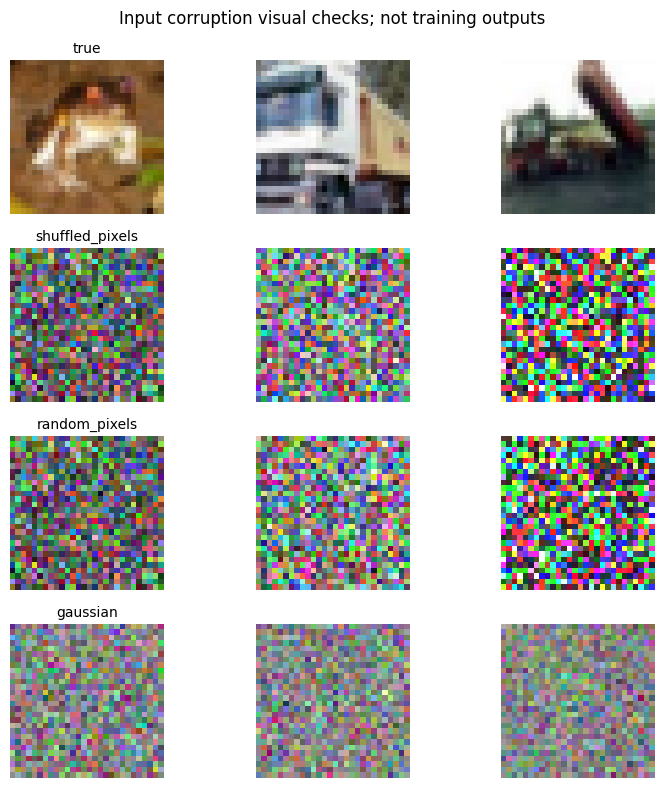

In [14]:
from matplotlib import pyplot as plt
small_imgs, small_labs = tr_probe_x[:3], tr_probe_y[:3]
global_raw = tr_probe_x[:,2:30,2:30,:].astype(np.float32)/255.
mu, sig = float(global_raw.mean()), float(global_raw.std())
modes = ['true', 'shuffled_pixels', 'random_pixels', 'gaussian']
fig, ax = plt.subplots(len(modes), 3, figsize=(8, 8))
for i, mode in enumerate(modes):
    ds = z.CIFARCondition(small_imgs, small_labs, image_mode=mode,
                          gaussian_mean=mu, gaussian_std=sig)
    for j in range(3):
        image, _ = ds[j]
        x = image.permute(1,2,0).numpy()
        x = (x - x.min()) / (x.max() - x.min() + 1e-8)  # display only
        ax[i,j].imshow(x)
        ax[i,j].set_axis_off()
        if j==0: ax[i,j].set_title(mode, fontsize=10)
plt.suptitle('Input corruption visual checks; not training outputs')
plt.tight_layout(); plt.show()

## 3. Run the small **software smoke test** first

This uses 1024 CIFAR-10 train examples, ~1000 test examples, **2 epochs**, and only four conditions: two Inception runs in the panel 1a subset and two MLP runs from the grid. The point is to uncover implementation/device/preprocessing bugs. **Do not interpret its learning curves as a paper reproduction**. All plots are still generated from actual training steps.

To make this fast on a CPU, you can use a CUDA Colab runtime; don't increase `smoke_size` until it works.

In [15]:
smoke_config = z.ExperimentConfig(
    run_mode='smoke', data_root='./data', out_dir='./zhang_results',
    batch_size=128, max_epochs=2, smoke_size=1024,
    num_workers=0, logging_interval_steps=5,
)
smoke_a, smoke_grid = z.run_all(smoke_config)
z.save_experiment_summary(smoke_a, smoke_grid, smoke_config.out_dir)
plt.close(z.plot_from_runs(smoke_a, smoke_grid, smoke_config.out_dir, smoke=True))
print('SMOKE TEST completed. These are not paper Figure 1 results.')

Device: cuda PyTorch: 2.11.0+cu130
Architecture diagnostics: [{'model': 'inception', 'params_actual': 1577306, 'params_paper': 1649402, 'difference': -72096}, {'model': 'alexnet', 'params_actual': 1387786, 'params_paper': 1387786, 'difference': 0}, {'model': 'mlp1', 'params_actual': 1209866, 'params_paper': 1209866, 'difference': 0}, {'model': 'mlp3', 'params_actual': 1735178, 'params_paper': 1735178, 'difference': 0}]
Data diagnostics: {'whitened_sample_mean': 2.0273688505767495e-08, 'whitened_sample_population_std': 1.0, 'p1_fraction_labels_actually_changed': 0.8984375, 'test_labels': 'Always original, never corrupted'}
inception_p0.00_true_n1024_smoke epoch 001  step 000008 train CE 2.2996  acc 15.0391% LR 0.1
inception_p0.00_true_n1024_smoke epoch 002  step 000016 train CE 2.5322  acc 18.2617% LR 0.095
inception_p1.00_true_n1024_smoke epoch 001  step 000008 train CE 2.3075  acc 8.8867% LR 0.1
inception_p1.00_true_n1024_smoke epoch 002  step 000016 train CE 2.3006  acc 12.2070% LR 0

/content/zhang_figure1_independent.py:618: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=8)


Saved: zhang_results/figure1_smoke.png
SMOKE TEST completed. These are not paper Figure 1 results.


## 4. Run the real CIFAR-10 experiments

Set `RUN_LONG_EXPERIMENTS = True` in the next cell when ready. This uses **50,000 training and 10,000 test examples**. It can require many GPU hours. The results are saved as a per-run JSON log in `out_dir`; `.pt` weights/optimizer/RNG checkpoints persist after every incomplete epoch.

- **`LONG_MODE='reduced'`**: Figure 1a all five conditions; Figure 1b/c three architectures at **p = 0, 0.5, 1**. Up to **12 distinct runs** with full data and schedule, but a **reduced corruption grid**. This is the realistic starting point.
- **`LONG_MODE='full'`**: panel 1a plus Inception / AlexNet / MLP 1x512 each at **p = 0, 0.1, ..., 1** (up to **36 distinct runs**), again full data and schedule.

**Convergence-time definition (we must report it):** for model `m` and p, `T_m(p)` is the first end-of-epoch full-training-set evaluation attaining **at least 99% classification accuracy**, measured in optimizer steps. Panel 1b plots `T_m(p) / T_m(0)`. Panel 1c measures test error on the **original** CIFAR-10 labels **at that first convergence checkpoint**. The paper does not prescribe a numerical criterion; our threshold is deliberately lower than 99.9% because Table 1 reports 99.34% accuracy for MLP 1×512 on p=1. Nonconverged runs are **censored**, never assigned fake times.

**Important:** The original paper's phrase *zero training error* is stricter than our operational threshold, so document this distinction. The notebook logs exact training error after every epoch to permit subsequent sensitivity analyses.

Device: cuda PyTorch: 2.11.0+cu130
Architecture diagnostics: [{'model': 'inception', 'params_actual': 1577306, 'params_paper': 1649402, 'difference': -72096}, {'model': 'alexnet', 'params_actual': 1387786, 'params_paper': 1387786, 'difference': 0}, {'model': 'mlp1', 'params_actual': 1209866, 'params_paper': 1209866, 'difference': 0}, {'model': 'mlp3', 'params_actual': 1735178, 'params_paper': 1735178, 'difference': 0}]
Data diagnostics: {'whitened_sample_mean': 2.0273688505767495e-08, 'whitened_sample_population_std': 1.0, 'p1_fraction_labels_actually_changed': 0.90016, 'test_labels': 'Always original, never corrupted'}
inception_p0.00_true_n50000_reduced epoch 001  step 000391 train CE 1.2173  acc 58.3600% LR 0.1
inception_p0.00_true_n50000_reduced epoch 002  step 000782 train CE 0.7432  acc 74.1760% LR 0.095
inception_p0.00_true_n50000_reduced epoch 003  step 001173 train CE 0.7180  acc 76.0180% LR 0.09025
inception_p0.00_true_n50000_reduced epoch 004  step 001564 train CE 0.4331  ac

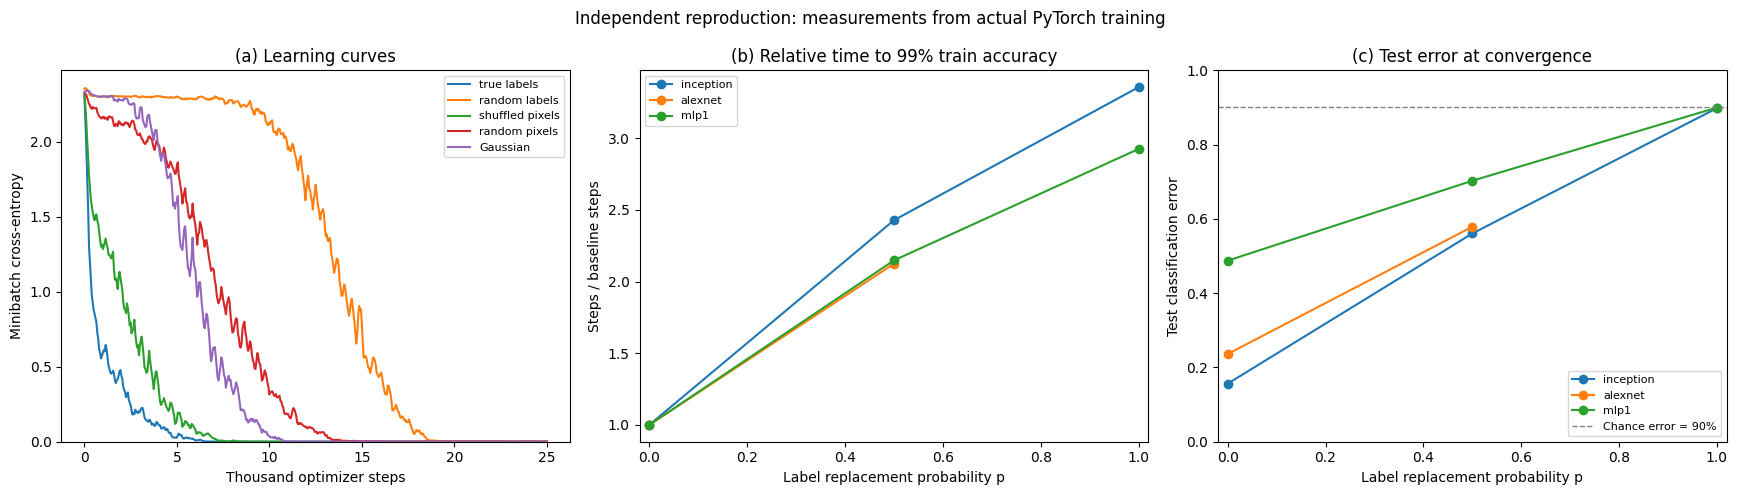

Saved real-training Figure 1 results to: ./zhang_results


In [16]:
RUN_LONG_EXPERIMENTS = True    # << Set to True only when ready for real CIFAR runs
LONG_MODE = 'reduced'          # 'reduced' or 'full'

# Optional Colab persistence:
# from google.colab import drive
# drive.mount('/content/drive')
# OUT_DIR = '/content/drive/MyDrive/zhang_figure1_results'
OUT_DIR = './zhang_results'

if RUN_LONG_EXPERIMENTS:
    long_config = z.ExperimentConfig(
        run_mode=LONG_MODE, data_root='./data', out_dir=OUT_DIR,
        batch_size=128, max_epochs=200, figure1a_max_steps=25_000,
        converge_train_accuracy=0.99,
        num_workers=0, logging_interval_steps=50, checkpoint=True,
        label_seed=2027, image_seed=990, init_seed=2026,
    )
    paper_a, paper_grid = z.run_all(long_config)
    z.save_experiment_summary(paper_a, paper_grid, long_config.out_dir)
    fig = z.plot_from_runs(paper_a, paper_grid, long_config.out_dir, smoke=False)
    plt.show()
    print('Saved real-training Figure 1 results to:', long_config.out_dir)
else:
    print('Long experiments NOT executed: set RUN_LONG_EXPERIMENTS=True to train on the full CIFAR-10 dataset.')

## 5. Inspect actual outcomes; document discrepancies

The following report is constructed only if the long experiment was **actually run in the current notebook session**. The JSON logs include: selected label fraction, actually changed label fraction, complete training accuracy and loss per epoch, LR per epoch, 99%-threshold crossing, test performance at that crossing, and run time.

Before attributing differences to the paper's conclusions, inspect: parameter counts, full training-set convergence, fixed labels, learning-rate decay, train-vs-test evaluation mode for batch normalization, the p=1 changed fraction, and potential censoring from the epoch budget.

In [1]:
if RUN_LONG_EXPERIMENTS:
    from pprint import pprint
    records = z.save_experiment_summary(paper_a, paper_grid, OUT_DIR)
    for row in records:
        pprint(row)
    print('Example training/LR history:')
    sample = next(iter(paper_a.values()))
    for v in sample['epoch_metrics'][:5]:
        print(v)
    print('Architecture mismatch:', [v for v in z.architecture_diagnostics() if v['difference'] != 0])
else:
    print('No full CIFAR-10 experiments run in this session. No reproduction results to inspect.')

NameError: name 'RUN_LONG_EXPERIMENTS' is not defined

In [2]:
import os, json
import numpy as np
import matplotlib.pyplot as plt

OUT_DIR = "./zhang_results"

def load_json(path):
    with open(path, "r") as f:
        return json.load(f)

# ---------- Figure 1a ----------
fig1a_runs = {
    "true labels": load_json(os.path.join(OUT_DIR, "inception_p0.00_true_n50000_reduced.json")),
    "random labels": load_json(os.path.join(OUT_DIR, "inception_p1.00_true_n50000_reduced.json")),
    "shuffled pixels": load_json(os.path.join(OUT_DIR, "inception_p0.00_shuffled_pixels_n50000_reduced.json")),
    "random pixels": load_json(os.path.join(OUT_DIR, "inception_p0.00_random_pixels_n50000_reduced.json")),
    "Gaussian": load_json(os.path.join(OUT_DIR, "inception_p0.00_gaussian_n50000_reduced.json")),
}

# ---------- Figure 1b / 1c ----------
models = ["inception", "alexnet", "mlp1"]
ps = [0.0, 0.5, 1.0]

runs = {}
for m in models:
    runs[m] = {}
    for p in ps:
        fn = os.path.join(OUT_DIR, f"{m}_p{p:.2f}_true_n50000_reduced.json")
        if os.path.exists(fn):
            runs[m][p] = load_json(fn)
        else:
            runs[m][p] = None

fig, axes = plt.subplots(1, 3, figsize=(19, 6))
ax1, ax2, ax3 = axes

# ---------------- Panel (a): learning curves ----------------
for label, run in fig1a_runs.items():
    steps = [x["step"] for x in run["batch_losses"]]
    losses = [x["loss"] for x in run["batch_losses"]]
    ax1.plot(np.array(steps) / 1000.0, losses, label=label)

ax1.set_title("(a) Learning curves")
ax1.set_xlabel("Thousand optimizer steps")
ax1.set_ylabel("Minibatch cross-entropy")
ax1.legend()

# ---------------- Panel (b): relative time to 99% train acc ----------------
# Converged runs -> solid line with circles
# Nonconverged runs -> dashed line with X markers, using full budget
for m in models:
    baseline = runs[m][0.0]
    if baseline is None or baseline.get("convergence_steps") is None:
        continue

    base_steps = baseline["convergence_steps"]

    x_conv, y_conv = [], []
    x_cens, y_cens = [], []

    for p in ps:
        r = runs[m][p]
        if r is None:
            continue

        if r.get("converged", False) and r.get("convergence_steps") is not None:
            x_conv.append(p)
            y_conv.append(r["convergence_steps"] / base_steps)
        else:
            # show censored point at full training budget
            x_cens.append(p)
            y_cens.append(r["training_steps"] / base_steps)

    if len(x_conv) > 0:
        ax2.plot(x_conv, y_conv, marker="o", label=m)

    if len(x_cens) > 0:
        ax2.plot(x_cens, y_cens, marker="x", linestyle="--", label=f"{m} (censored)")

ax2.set_title("(b) Relative time to 99% train accuracy")
ax2.set_xlabel("Label replacement probability p")
ax2.set_ylabel("Steps / baseline steps")
ax2.set_xticks(ps)
ax2.legend()

# ---------------- Panel (c): test error ----------------
# Converged runs -> test_at_convergence
# Nonconverged runs -> test_at_end, shown as censored
for m in models:
    x_conv, y_conv = [], []
    x_cens, y_cens = [], []

    for p in ps:
        r = runs[m][p]
        if r is None:
            continue

        if r.get("converged", False) and r.get("test_at_convergence") is not None:
            err = 1.0 - r["test_at_convergence"]["accuracy"]
            x_conv.append(p)
            y_conv.append(err)
        elif r.get("test_at_end") is not None:
            err = 1.0 - r["test_at_end"]["accuracy"]
            x_cens.append(p)
            y_cens.append(err)

    if len(x_conv) > 0:
        ax3.plot(x_conv, y_conv, marker="o", label=m)

    if len(x_cens) > 0:
        ax3.plot(x_cens, y_cens, marker="x", linestyle="--", label=f"{m} (censored)")

ax3.axhline(0.9, linestyle="--", color="gray", label="Chance error = 90%")
ax3.set_title("(c) Test error")
ax3.set_xlabel("Label replacement probability p")
ax3.set_ylabel("Test classification error")
ax3.set_xticks(ps)
ax3.set_ylim(0, 1.0)
ax3.legend()

plt.suptitle("Independent reproduction: actual PyTorch training\n(censored runs shown with dashed lines and X markers)", y=1.03)
plt.tight_layout()

save_path = os.path.join(OUT_DIR, "figure1_reproduction_with_censored.png")
plt.savefig(save_path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved:", save_path)

# Helpful printout for AlexNet p=1
alex_p0 = runs["alexnet"][0.0]
alex_p1 = runs["alexnet"][1.0]
if alex_p0 is not None and alex_p1 is not None:
    rel = alex_p1["training_steps"] / alex_p0["convergence_steps"]
    test_err_end = 1.0 - alex_p1["test_at_end"]["accuracy"]
    print(f"AlexNet p=1 censored relative time: {rel:.4f}")
    print(f"AlexNet p=1 end-of-budget test error: {test_err_end:.4f}")

FileNotFoundError: [Errno 2] No such file or directory: './zhang_results/inception_p0.00_true_n50000_reduced.json'

## 6. Reproducibility and submission checklist

- [ ] Run and retain preprocessing and architecture diagnostics (especially **unresolved Inception count**).
- [ ] Finish CIFAR-10 runs or explicitly report which are censored under the epoch budget.
- [ ] Explain why expected actual label-change fraction is `0.9p` and why p=1 test error is approximately `0.9`.
- [ ] Report all optimizer settings, per-image whitening, crop order, lack of augmentation/weight decay/dropout, batch size, seeds, dataset sizes and GPU.
- [ ] Report `>=99%` operational convergence, why it differs from literal zero error, and the epoch-boundary granularity.
- [ ] Record which grid was used: `reduced` `{0, 0.5, 1}` or `full` `{0, 0.1, ..., 1}`.
- [ ] Compare measured curves to Figure 1, **with measured evidence and condition-wise diagnostics**, not invented reasons.
- [ ] Update `DECISIONS.md` with actual failures, corrections, hardware, time and results.
- [ ] Commit the **independent** notebook/source/results to Git before reading any author's/third-party implementation (Phase 4).
- [ ] Add the shared GPT-6 conversation URL and public GitHub URL to the assignment report; follow the instructor's release timing.

**Known limitation:** Appendix Figure 3's reconstructed Inception size does not match the 1,649,402 parameters in Table 1; see `DECISIONS.md`. Avoid describing it as an exact reimplementation until that discrepancy is resolved.